# Tuần 06 — Khái quát dữ liệu (2/7)

**UET.MAT1052 — Xác suất thống kê**

**Hoàng Thị Điệp · Nghiêm Nguyễn Việt Dũng · Lê Thị Hường**

*Khoa Công nghệ Thông tin (VNU-UET-FIT)*

## Notebook minh họa

### Phân phối xác suất và biến ngẫu nhiên rời rạc

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

SEED = 214

# 1. Phân phối xác suất và tần suất thực nghiệm

## 1.1. Ví dụ 1 — Rút thăm từ hộp $\{1,2,2,3,4\}$

$$p_X = (0.2,\ 0.4,\ 0.2,\ 0.2)\ \text{tại}\ x=1,2,3,4.$$

`replace=True` mô phỏng rút có hoàn lại; tần suất là trung bình của các giá trị đúng/sai.

In [2]:
rng = np.random.default_rng(SEED)
hop = [1, 2, 2, 3, 4]
mau = rng.choice(hop, size=5000, replace=True)
x = np.arange(1, 5)
p_hop = [0.2, 0.4, 0.2, 0.2]

for m in [50, 500, 5000]:
    tan_suat = [(mau[:m] == k).mean() for k in x]
    print(m, np.round(tan_suat, 3))

50 [0.26 0.34 0.2  0.2 ]
500 [0.21  0.402 0.188 0.2  ]
5000 [0.207 0.394 0.204 0.195]


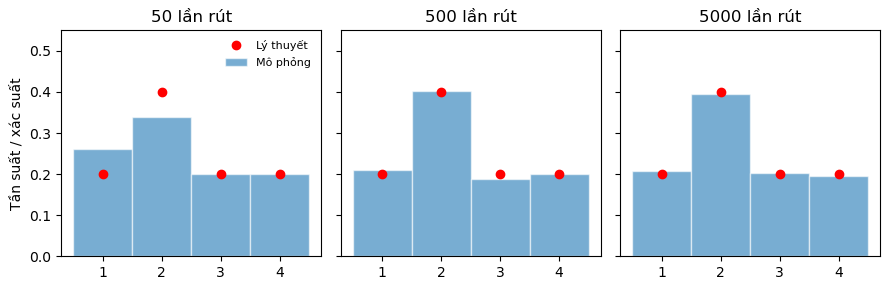

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(9, 3), sharey=True)
for ax, m in zip(axes, [50, 500, 5000]):
    f = [(mau[:m] == k).mean() for k in x]
    ax.bar(x, f, width=1, alpha=0.6, edgecolor="white", label="Mô phỏng")
    ax.plot(x, p_hop, "ro", label="Lý thuyết")
    ax.set(xticks=x, ylim=(0, 0.55), title=f"{m} lần rút")
axes[0].set_ylabel("Tần suất / xác suất")
axes[0].legend(fontsize=8, frameon=False)
plt.tight_layout()
plt.show()

Cỡ mẫu tăng thì tần suất thường gần xác suất lý thuyết hơn, nhưng sai lệch không nhất thiết giảm sau mỗi lần tăng.

## 1.2. Ví dụ 2 — Tổng số chấm hai xúc xắc

$$P(X=2)=\frac1{36},\qquad P(X=7)=\frac6{36}.$$

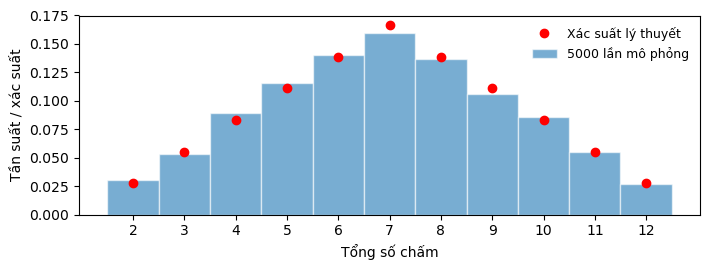

Tần suất tổng 7: 0.1598
Xác suất tổng 7: 0.1667


In [4]:
rng = np.random.default_rng(SEED)
tong = rng.integers(1, 7, size=(5000, 2)).sum(axis=1)
x_dice = np.arange(2, 13)
p_dice = np.array([1, 2, 3, 4, 5, 6, 5, 4, 3, 2, 1]) / 36
f_dice = [(tong == k).mean() for k in x_dice]

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.bar(x_dice, f_dice, width=1, alpha=0.6, edgecolor="white", label="5000 lần mô phỏng")
ax.plot(x_dice, p_dice, "ro", label="Xác suất lý thuyết")
ax.set(xlabel="Tổng số chấm", ylabel="Tần suất / xác suất", xticks=x_dice)
ax.legend(fontsize=9, frameon=False)
plt.tight_layout()
plt.show()

print("Tần suất tổng 7:", round((tong == 7).mean(), 4))
print("Xác suất tổng 7:", round(6/36, 4))

# 2. Hàm phân phối tích lũy

$F_X(x)=P(X\le x)$ là hàm bậc thang, liên tục bên phải; độ nhảy tại $k$ bằng $P(X=k)$.

In [5]:
def ve_cdf(xs, ps, xlabel="x"):
    F = np.cumsum(ps)
    edges = np.r_[xs[0] - 1, xs, xs[-1] + 1]
    levels = np.r_[0, F]
    fig, ax = plt.subplots(figsize=(7.2, 2.8))
    for a, b, y in zip(edges[:-1], edges[1:], levels):
        ax.hlines(y, a, b, color="#386da8", linewidth=2)
    ax.scatter(xs, np.r_[0, F[:-1]], facecolors="white", edgecolors="#386da8", zorder=3)
    ax.scatter(xs, F, color="#386da8", zorder=4)
    ax.set(xlabel=xlabel, ylabel="F(x)", xticks=xs, ylim=(-0.08, 1.08))
    ax.grid(alpha=0.2)
    plt.tight_layout()
    plt.show()
    return F

## 2.1. Ví dụ 6–7 — Hai sản phẩm, mỗi sản phẩm đạt chuẩn với xác suất 0.8

$$P(0<X\le2)=F_X(2)-F_X(0)=0.96,\qquad P(X=1)=F_X(1)-F_X(0)=0.32.$$

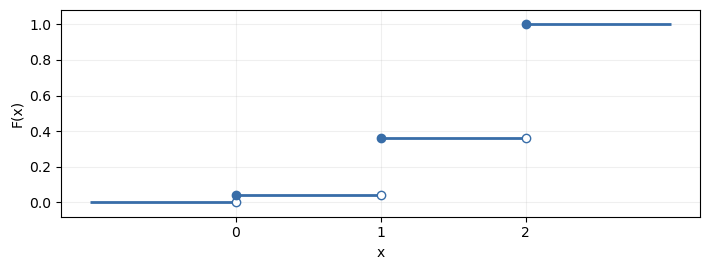

F = [0.04 0.36 1.  ]
P(0 < X <= 2) = 0.96
P(X < 2) = F(1) = 0.36
P(X = 1) = 0.32


In [6]:
F2 = ve_cdf(np.arange(3), np.array([0.04, 0.32, 0.64]))
print("F =", np.round(F2, 2))
print("P(0 < X <= 2) =", round(F2[2] - F2[0], 2))
print("P(X < 2) = F(1) =", round(F2[1], 2))
print("P(X = 1) =", round(F2[1] - F2[0], 2))

## 2.2. Ví dụ 8 — Sáu đường dây điện thoại

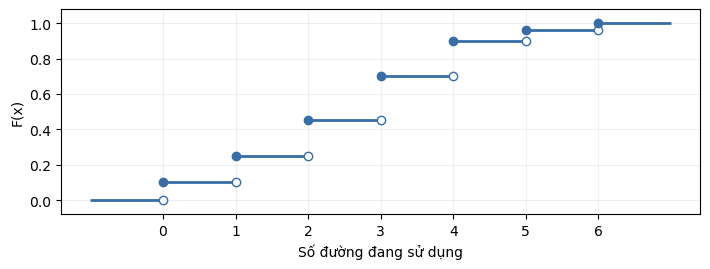

F = [0.1  0.25 0.45 0.7  0.9  0.96 1.  ]
P(X <= 3)        = 0.7
P(X < 3)         = 0.45
P(2 <= 6-X <= 4) = 0.65


In [7]:
x_phone = np.arange(7)
p_phone = np.array([.10, .15, .20, .25, .20, .06, .04])
F_phone = ve_cdf(x_phone, p_phone, "Số đường đang sử dụng")

print("F =", np.round(F_phone, 2))
print("P(X <= 3)        =", round(p_phone[x_phone <= 3].sum(), 2))
print("P(X < 3)         =", round(p_phone[x_phone < 3].sum(), 2))
print("P(2 <= 6-X <= 4) =", round(p_phone[(x_phone >= 2) & (x_phone <= 4)].sum(), 2))

# 3. Các phân phối rời rạc thông dụng

## 3.1. Ví dụ 9 — Phân phối đều rời rạc (xúc xắc)

$$P(X\ge5)=\frac13.$$

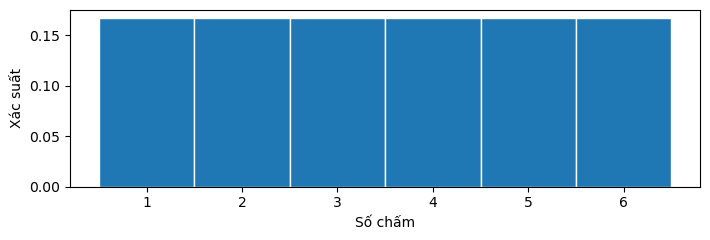

P(X >= 5) = 0.3333


In [8]:
fig, ax = plt.subplots(figsize=(7.2, 2.5))
ax.bar(range(1, 7), [1/6] * 6, width=1, edgecolor="white")
ax.set(xlabel="Số chấm", ylabel="Xác suất", xticks=range(1, 7))
plt.tight_layout()
plt.show()

print("P(X >= 5) =", round(stats.randint.sf(4, 1, 7), 4))

## 3.2. Ví dụ 11 — Bernoulli từ phép chọn đều trên $\{1,\ldots,1000\}$

In [9]:
N = np.arange(1, 1001)
print("P(N chia hết cho 3)  =", (N % 3 == 0).mean())
print("P(N chia hết cho 5)  =", (N % 5 == 0).mean())
print("P(N chia hết cho 15) =", (N % 15 == 0).mean())

P(N chia hết cho 3)  = 0.333
P(N chia hết cho 5)  = 0.2
P(N chia hết cho 15) = 0.066


$Y\sim\operatorname{Bernoulli}(0.333)$: $N$ đều nhưng $Y$ không đều trên $\{0,1\}$.

## 3.3. Ví dụ 12–13 — Phân phối nhị thức

- Ví dụ 12: $X\sim\operatorname{Binomial}(20,0.25)$.
- Ví dụ 13: $X\sim\operatorname{Binomial}(12,0.95)$.

In [10]:
print("VD12  P(X = 8)   =", round(stats.binom.pmf(8, n=20, p=0.25), 4))
print("VD12  P(X > 2)   =", round(stats.binom.sf(2, n=20, p=0.25), 4))
print("VD13  P(X = 11)  =", round(stats.binom.pmf(11, n=12, p=0.95), 4))
print("VD13  P(X >= 11) =", round(stats.binom.sf(10, n=12, p=0.95), 4))

VD12  P(X = 8)   = 0.0609
VD12  P(X > 2)   = 0.9087
VD13  P(X = 11)  = 0.3413
VD13  P(X >= 11) = 0.8816


## 3.4. Ví dụ 14 — Phân phối siêu bội

$X\sim\operatorname{Hypergeometric}(10,6,3)$. Trong SciPy: `M` = tổng số lá, `n` = số lá ghi 1, `N` = cỡ mẫu.

[0.0333 0.3    0.5    0.1667]


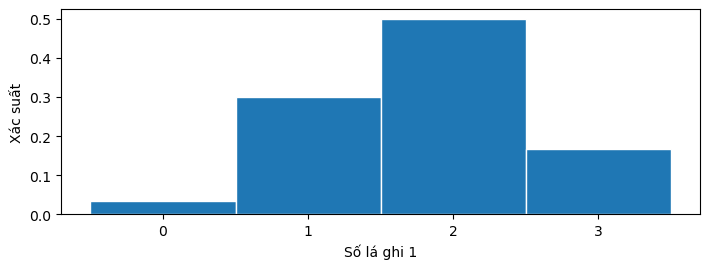

In [11]:
k = np.arange(4)
pmf_hyper = stats.hypergeom.pmf(k, M=10, n=6, N=3)
print(np.round(pmf_hyper, 4))

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.bar(k, pmf_hyper, width=1, edgecolor="white")
ax.set(xlabel="Số lá ghi 1", ylabel="Xác suất", xticks=k)
plt.tight_layout()
plt.show()

Mô phỏng: `replace=False` chỉ áp dụng trong mỗi bộ ba lá; mỗi lần lặp bắt đầu lại với hộp đủ 10 lá.

In [12]:
rng = np.random.default_rng(SEED)
hop01 = [1] * 6 + [0] * 4
ket_qua = np.array([rng.choice(hop01, size=3, replace=False).sum() for _ in range(5000)])

print("Tần suất X = 2:", round((ket_qua == 2).mean(), 4))
print("Xác suất X = 2:", round(stats.hypergeom.pmf(2, M=10, n=6, N=3), 4))

Tần suất X = 2: 0.5004
Xác suất X = 2: 0.5


## 3.5. Ví dụ 15 — Chấm 15 bài trong 50 bài

$X\sim\operatorname{Hypergeometric}(50,30,15)$.

In [13]:
X15 = stats.hypergeom(M=50, n=30, N=15)
print("P(X = 10)              =", round(X15.pmf(10), 4))
print("P(X >= 10 hoặc X <= 5) =", round(X15.sf(9) + X15.cdf(5), 4))

P(X = 10)              = 0.207
P(X >= 10 hoặc X <= 5) = 0.3938


## 3.6. Ví dụ 16 — Có hoàn lại và không hoàn lại

Có hoàn lại: $\operatorname{Binomial}(3,1/2)$; không hoàn lại: $\operatorname{Hypergeometric}(4,2,3)$.

Có hoàn lại   : [0.125 0.375 0.375 0.125]
Không hoàn lại: [0.  0.5 0.5 0. ]


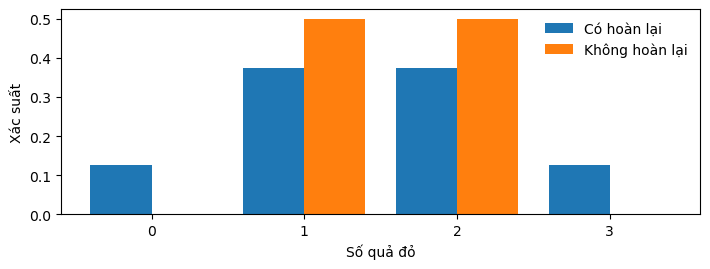

In [14]:
k = np.arange(4)
p_co = stats.binom.pmf(k, n=3, p=0.5)
p_khong = stats.hypergeom.pmf(k, M=4, n=2, N=3)
print("Có hoàn lại   :", np.round(p_co, 4))
print("Không hoàn lại:", np.round(p_khong, 4))

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.bar(k - 0.2, p_co, width=0.4, label="Có hoàn lại")
ax.bar(k + 0.2, p_khong, width=0.4, label="Không hoàn lại")
ax.set(xlabel="Số quả đỏ", ylabel="Xác suất", xticks=k)
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

## 3.7. Ví dụ 17–18 — Phân phối Poisson

Trong SciPy, `mu` tương ứng với $\lambda$. Trong 3 giây (VD18), tham số là $3\times4=12$.

VD17  P(X = 1)  = 0.3679
VD17  P(X <= 1) = 0.7358
VD18  P(X = 0)  = 0.0183
VD18  P(X > 6)  = 0.1107


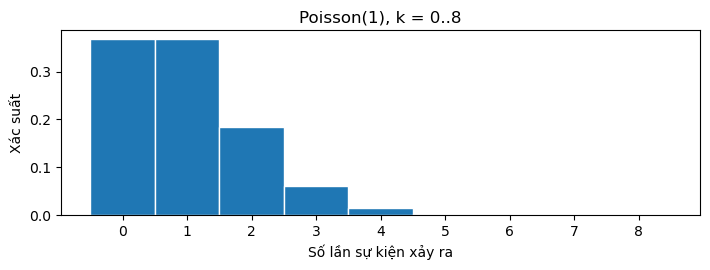

In [15]:
print("VD17  P(X = 1)  =", round(stats.poisson.pmf(1, mu=1), 4))
print("VD17  P(X <= 1) =", round(stats.poisson.cdf(1, mu=1), 4))
print("VD18  P(X = 0)  =", round(stats.poisson.pmf(0, mu=4), 4))
print("VD18  P(X > 6)  =", round(stats.poisson.sf(6, mu=4), 4))

k = np.arange(9)
fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.bar(k, stats.poisson.pmf(k, mu=1), width=1, edgecolor="white")
ax.set(xlabel="Số lần sự kiện xảy ra", ylabel="Xác suất", xticks=k, title="Poisson(1), k = 0..8")
plt.tight_layout()
plt.show()

# 4. Tính xác suất bằng SciPy

`pmf`: $P(X=x)$ · `cdf`: $P(X\le x)$ · `sf`: $P(X>x)$.

In [16]:
p_dung_11 = stats.binom.pmf(11, n=12, p=0.95)
p_it_nhat_11 = stats.binom.sf(10, n=12, p=0.95)
p_qua_6 = stats.poisson.sf(6, mu=4)
p_dung_2 = stats.hypergeom.pmf(2, M=30, n=6, N=5)

print("Đúng 11 sản phẩm    :", round(p_dung_11, 4))
print("Ít nhất 11 sản phẩm :", round(p_it_nhat_11, 4))
print("Hơn 6 yêu cầu       :", round(p_qua_6, 4))
print("Đúng 2 linh kiện lỗi:", round(p_dung_2, 4))

Đúng 11 sản phẩm    : 0.3413
Ít nhất 11 sản phẩm : 0.8816
Hơn 6 yêu cầu       : 0.1107
Đúng 2 linh kiện lỗi: 0.213
